In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyarrow
import seaborn as sns

In [32]:
jan_wide = pd.read_parquet('/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/anem-turbines/Alta10_Turbine_Points_10m_2026-01.parquet')
feb_wide = pd.read_parquet('/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/anem-turbines/Alta10_Turbine_Points_10m_2026-02.parquet')
mar_wide = pd.read_parquet('/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/anem-turbines/Alta10_Turbine_Points_10m_2026-03.parquet')
apr_wide = pd.read_parquet('/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/anem-turbines/Alta10_Turbine_Points_10m_2026-04.parquet')
may_wide = pd.read_parquet('/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/anem-turbines/Alta10_Turbine_Points_10m_2026-05.parquet')
jun_wide = pd.read_parquet('/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/anem-turbines/Alta10_Turbine_Points_10m_2026-06.parquet')
jul_wide = pd.read_parquet('/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/anem-turbines/Alta10_Turbine_Points_10m_2026-07.parquet')
aug_wide = pd.read_parquet('/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/anem-turbines/Alta10_Turbine_Points_10m_2026-08.parquet')
sep_wide = pd.read_parquet('/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/anem-turbines/Alta10_Turbine_Points_10m_2026-09.parquet')

ArrowInvalid: Could not open Parquet input source '<Buffer>': Parquet magic bytes not found in footer. Either the file is corrupted or this is not a parquet file.

In [39]:
# reordering and renaming variables with a dictionary
mapping1 = {'timestamp': 'utc', 'turbine': 'turbine', 'AirDensity': 'aid_density', 'KPI-TemperatureAmbient-Merged': 'KPI_temp_ambient_merged', 
           'KPI-TemperatureAmbient': 'KPI_temp_ambient', 'KPI-TheoreticalPower': 'KPI_theoretical_power', 'KPI-RealPowerAC': 'KPI_real_power_ac',
           'RealPowerAC': 'real_power_ac', 'KPI-WindSpeed': 'KPI_wind_speed', 'WindSpeed': 'wind_speed', 'WindDirection': 'wind_direction', 
           'WindDirectionRelative': 'wind_direction_relative', 'NacellePosition': 'nacelle_pos', 'BladePosition1': 'blade_1_pos', 
           'BladePosition2': 'blade_2_pos', 'BladePosition3': 'blade_3_pos', 'BladeSetpointPosition1': 'blade_1_setpos', 
           'BladeSetpointPosition2': 'blade_2_setpos', 'BladeSetpointPosition3': 'blade_3_setpos'}

# defining a function to convert the wide format datasets into long format datasets
def reshape_month_turbine(df):
    # defines utcTime as index for rows in new dataset
    df = df.set_index('timestamp')

    # splits the columns into the turbine name and variable name
    parts = df.columns.str.extract(r"^ALTA\d+-SCEWF-(WTG\d+)-(.+)$")
    parts.columns = ['turbine', 'variable']

    # outputs problematic columns from this split
    bad = df.columns[parts['turbine'].isna()]
    if len(bad):
        raise ValueError(f"Columns that didn't match the pattern: {list(bad)}")

    # creates a copy of the dataframe
    df = df.copy()
    df.columns = pd.MultiIndex.from_frame(parts)

    # creates the long version of the dataset
    long = df.stack(level = 'turbine', future_stack = True).reset_index()
    long['turbine'] = long['turbine'].astype(str)
    long.columns.name = None
    long.sort_values(['turbine', 'timestamp']).reset_index(drop = True)

    # returns new dataset with renamed and reordered columns
    return long[list(mapping1)].rename(columns = mapping1)

In [8]:
# applying the reshape_month_turbine() function to each monthly dataset
jan = reshape_month_turbine(jan_wide)
feb = reshape_month_turbine(feb_wide)
mar = reshape_month_turbine(mar_wide)
apr = reshape_month_turbine(apr_wide)
may = reshape_month_turbine(may_wide)
jun = reshape_month_turbine(jun_wide)
jul = reshape_month_turbine(jul_wide)
aug = reshape_month_turbine(aug_wide)
sep = reshape_month_turbine(sep_wide)

In [9]:
jan

,utc,turbine,aid_density,KPI_temp_ambient_merged,KPI_temp_ambient,KPI_theoretical_power,KPI_real_power_ac,real_power_ac,KPI_wind_speed,wind_speed,wind_direction,wind_direction_relative,nacelle_pos,blade_1_pos,blade_2_pos,blade_3_pos,blade_1_setpos,blade_2_setpos,blade_3_setpos
0,2026-01-01 08:00:00,WTG150,1.092081,8.299405,8.299405,746.68463,672.605100,670.286714,6.906036,6.907681,115.629870,-1.392857,118.785714,NaN,-1.056245,-0.643520,2.307242,-0.892182,-0.471435
1,2026-01-01 08:00:00,WTG151,1.087094,9.592089,9.592089,406.01855,485.577940,485.492347,5.730449,5.717620,116.709677,6.439716,113.500000,0.614472,-0.925170,1.124203,0.856155,-0.676644,1.384543
2,2026-01-01 08:00:00,WTG152,1.090355,8.745550,8.745550,440.09213,497.796050,496.384967,5.862610,5.836812,252.291139,-5.909091,259.600000,-0.481281,0.200810,0.278822,NaN,NaN,NaN
3,2026-01-01 08:00:00,WTG153,1.044950,21.009600,21.009600,445.82935,423.571320,422.188638,5.969328,5.951737,283.955414,-6.215278,291.230769,-0.059970,0.342474,-0.278986,-0.027131,0.376825,-0.244748
4,2026-01-01 08:00:00,WTG154,1.088453,9.238713,9.238713,208.84138,274.527680,274.276035,4.760764,4.757731,139.118343,-4.608108,140.000000,-1.428621,1.907079,1.215503,-1.376194,1.938141,1.257423
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209803,2026-02-01 07:50:00,WTG193,1.049257,20.110878,20.110878,310.39447,214.046050,214.396638,5.363252,5.367672,75.134615,-3.197279,77.777778,0.179872,0.514837,0.032808,0.175948,0.508853,0.027182
209804,2026-02-01 07:50:00,WTG194,1.053832,18.836517,18.836517,0.00000,0.000000,NaN,2.471131,2.469988,38.305556,-4.694444,NaN,NaN,NaN,NaN,NaN,NaN,NaN
209805,2026-02-01 07:50:00,WTG195,1.053648,18.887512,18.887512,0.00000,56.520897,56.311950,2.613477,2.603995,118.868966,-2.930070,120.500000,1.655098,2.393117,1.870419,NaN,NaN,NaN
209806,2026-02-01 07:50:00,WTG196,1.052941,19.083797,19.083797,185.80700,94.695724,94.803883,4.672840,4.671526,90.565789,-2.767123,95.166667,1.353469,1.958733,1.588099,1.319824,1.940077,1.561138


In [10]:
jan["utc"] = pd.to_datetime(jan["utc"])
feb["utc"] = pd.to_datetime(feb["utc"])
mar["utc"] = pd.to_datetime(mar["utc"])
apr["utc"] = pd.to_datetime(apr["utc"])

In [13]:
wtg150 = jan.loc[jan["turbine"] == "WTG150"]

In [14]:
wtg150

,utc,turbine,aid_density,KPI_temp_ambient_merged,KPI_temp_ambient,KPI_theoretical_power,KPI_real_power_ac,real_power_ac,KPI_wind_speed,wind_speed,wind_direction,wind_direction_relative,nacelle_pos,blade_1_pos,blade_2_pos,blade_3_pos,blade_1_setpos,blade_2_setpos,blade_3_setpos
0,2026-01-01 08:00:00,WTG150,1.092081,8.299405,8.299405,746.68463,672.60510,670.286714,6.906036,6.907681,115.629870,-1.392857,118.785714,NaN,-1.056245,-0.643520,2.307242,-0.892182,-0.471435
47,2026-01-01 08:10:00,WTG150,0.800856,8.573889,8.573889,466.00030,541.30096,542.747853,6.609679,6.592723,107.211538,-10.056738,117.066667,NaN,-1.077751,-0.680390,2.354385,-0.845038,-0.424893
94,2026-01-01 08:20:00,WTG150,1.089478,8.972823,8.972823,292.86000,237.94884,239.185173,5.210308,5.229490,122.834356,0.734694,118.812500,NaN,-0.445800,-0.039797,2.813232,-0.386191,0.032674
141,2026-01-01 08:30:00,WTG150,0.800936,8.531316,8.531316,443.03992,503.22354,504.556470,6.510418,6.512685,121.493151,-6.506849,NaN,NaN,-1.205972,-0.786801,NaN,NaN,NaN
188,2026-01-01 08:40:00,WTG150,1.090836,8.621079,8.621079,500.71185,444.42767,444.157211,6.093416,6.106378,121.117241,-8.119718,130.000000,NaN,-1.205672,-0.786363,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209573,2026-02-01 07:10:00,WTG150,1.053385,18.960490,18.960490,0.00000,0.05158,7.736964,2.957094,2.956791,96.240000,-1.794521,100.000000,NaN,4.080153,4.090746,4.318937,4.094210,4.104477
209620,2026-02-01 07:20:00,WTG150,1.052123,19.311193,19.311193,0.00000,0.00000,NaN,3.119072,3.106109,103.171975,-1.932886,105.000000,NaN,5.644671,5.642931,5.656648,5.658021,5.637986
209667,2026-02-01 07:30:00,WTG150,1.052318,19.256907,19.256907,0.00000,0.00000,NaN,3.376390,3.378169,107.000000,-2.000000,NaN,NaN,20.777641,20.777846,20.714224,20.714224,20.533077
209714,2026-02-01 07:40:00,WTG150,1.054639,18.612710,18.612710,0.00000,0.00000,NaN,3.659376,3.647962,109.000000,-5.734694,112.500000,NaN,47.652470,47.758788,48.824902,48.824902,48.752768


Text(0, 0.5, 'frequency (probability)')

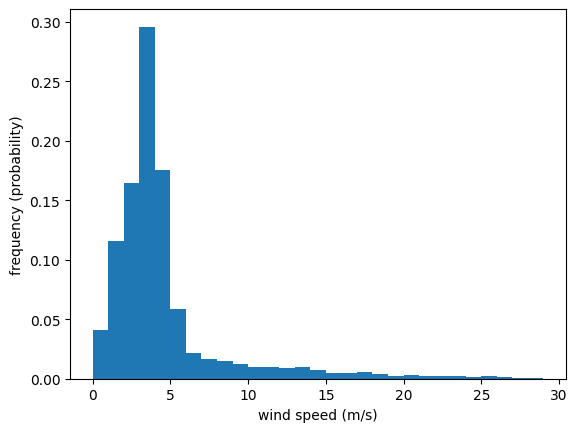

In [16]:
import matplotlib.pyplot as plt
import numpy as np

plt.hist(wtg150["wind_speed"], bins=np.arange(0, 30, 1), density=True)
plt.xlabel("wind speed (m/s)")
plt.ylabel("frequency (probability)")

lidar

In [3]:
path = "/Users/phaemaurice/Documents/GitHub/CU-Capstone-Project/data-capstone/lidar_data/10_minute/06_24_2026_to_8_5_2026/WTG_159.csv"

wtg159 = pd.read_csv(path)

In [4]:
wtg159

,Timestamp,v,v_std,phi,availability,control,sensor1_v,sensor1_v_std,sensor2_v,sensor2_v_std,sensor1_phi,sensor2_phi
0,2026-06-24 00:00:00,5.10,1.41,11.90,460,0,6.12,1.50,0.0,0.0,-13.29,0.0
1,2026-06-24 00:10:00,4.27,1.09,8.61,545,0,5.65,1.25,0.0,0.0,-6.38,0.0
2,2026-06-24 00:20:00,4.88,1.47,13.29,566,0,5.72,1.16,0.0,0.0,-4.67,0.0
3,2026-06-24 00:30:00,7.08,1.46,20.81,567,0,6.71,1.46,0.0,0.0,-8.77,0.0
4,2026-06-24 00:40:00,6.91,0.98,17.79,564,2,6.45,1.40,0.0,0.0,-13.02,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
5114,2026-08-04 23:10:00,7.06,1.04,2.67,588,0,9.21,1.40,0.0,0.0,-4.83,0.0
5115,2026-08-04 23:20:00,6.87,1.07,1.47,595,0,8.93,1.37,0.0,0.0,-7.84,0.0
5116,2026-08-04 23:30:00,7.29,1.04,5.82,590,0,9.30,1.36,0.0,0.0,-7.46,0.0
5117,2026-08-04 23:40:00,7.59,1.18,5.35,585,0,9.74,1.52,0.0,0.0,-5.84,0.0


In [4]:
wtg159["Timestamp"] = pd.to_datetime(wtg159["Timestamp"])

In [6]:
wtg159

,Timestamp,v,v_std,phi,availability,control,sensor1_v,sensor1_v_std,sensor2_v,sensor2_v_std,sensor1_phi,sensor2_phi
0,2026-06-24 00:00:00,5.10,1.41,11.90,460,0,6.12,1.50,0.0,0.0,-13.29,0.0
1,2026-06-24 00:10:00,4.27,1.09,8.61,545,0,5.65,1.25,0.0,0.0,-6.38,0.0
2,2026-06-24 00:20:00,4.88,1.47,13.29,566,0,5.72,1.16,0.0,0.0,-4.67,0.0
3,2026-06-24 00:30:00,7.08,1.46,20.81,567,0,6.71,1.46,0.0,0.0,-8.77,0.0
4,2026-06-24 00:40:00,6.91,0.98,17.79,564,2,6.45,1.40,0.0,0.0,-13.02,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
5114,2026-08-04 23:10:00,7.06,1.04,2.67,588,0,9.21,1.40,0.0,0.0,-4.83,0.0
5115,2026-08-04 23:20:00,6.87,1.07,1.47,595,0,8.93,1.37,0.0,0.0,-7.84,0.0
5116,2026-08-04 23:30:00,7.29,1.04,5.82,590,0,9.30,1.36,0.0,0.0,-7.46,0.0
5117,2026-08-04 23:40:00,7.59,1.18,5.35,585,0,9.74,1.52,0.0,0.0,-5.84,0.0


In [5]:
path = "/Users/phaemaurice/Documents/GitHub/CU-Capstone-Project/data-capstone/lidar_data/10_minute/06_24_2026_to_8_5_2026/WTG_170.csv"
wtg170 = pd.read_csv(path)
wtg170["Timestamp"] = pd.to_datetime(wtg170["Timestamp"])

In [8]:
wtg170

,Timestamp,v,v_std,phi,availability,control,sensor1_v,sensor1_v_std,sensor2_v,sensor2_v_std,sensor1_phi,sensor2_phi
0,2026-06-24 00:00:00,7.07,1.01,-0.62,585.0,0,8.44,1.57,0.0,0.0,-10.41,0.0
1,2026-06-24 00:10:00,6.43,1.13,-1.79,563.0,0,7.92,1.41,0.0,0.0,-8.33,0.0
2,2026-06-24 00:20:00,6.79,0.85,-1.19,577.0,0,7.89,1.28,0.0,0.0,-4.62,0.0
3,2026-06-24 00:30:00,6.37,0.90,-1.74,592.0,0,7.29,1.31,0.0,0.0,-1.36,0.0
4,2026-06-24 00:40:00,6.66,0.85,1.63,593.0,2,8.02,1.18,0.0,0.0,0.55,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
5113,2026-08-04 23:10:00,7.13,0.97,-5.04,595.0,1,9.07,1.24,0.0,0.0,-13.02,0.0
5114,2026-08-04 23:20:00,8.05,0.95,1.39,595.0,1,10.04,1.32,0.0,0.0,-4.89,0.0
5115,2026-08-04 23:30:00,7.77,1.28,-3.47,595.0,2,9.90,1.39,0.0,0.0,-11.80,0.0
5116,2026-08-04 23:40:00,7.57,0.98,-1.20,594.0,2,9.38,1.35,0.0,0.0,-7.74,0.0


In [6]:
path3 = "/Users/phaemaurice/Documents/GitHub/CU-Capstone-Project/data-capstone/lidar_data/10_minute/06_24_2026_to_8_5_2026/WTG_171.csv"
path4 = "/Users/phaemaurice/Documents/GitHub/CU-Capstone-Project/data-capstone/lidar_data/10_minute/06_24_2026_to_8_5_2026/WTG_173.csv"
path5 = "/Users/phaemaurice/Documents/GitHub/CU-Capstone-Project/data-capstone/lidar_data/10_minute/06_24_2026_to_8_5_2026/WTG_180.csv"
path6 = "/Users/phaemaurice/Documents/GitHub/CU-Capstone-Project/data-capstone/lidar_data/10_minute/06_24_2026_to_8_5_2026/WTG_184.csv"

wtg171 = pd.read_csv(path3)
wtg171["Timestamp"] = pd.to_datetime(wtg171["Timestamp"])

wtg173 = pd.read_csv(path4)
wtg173["Timestamp"] = pd.to_datetime(wtg173["Timestamp"])

wtg180 = pd.read_csv(path5)
wtg180["Timestamp"] = pd.to_datetime(wtg180["Timestamp"])

wtg184 = pd.read_csv(path6)
wtg184["Timestamp"] = pd.to_datetime(wtg184["Timestamp"])

In [8]:
path159 = "/Users/phaemaurice/Documents/GitHub/CU-Capstone-Project/data-capstone/lidar_data/10_minute/2026_04_01_to_2026_06_25/WTG_159.csv"
path170 = "/Users/phaemaurice/Documents/GitHub/CU-Capstone-Project/data-capstone/lidar_data/10_minute/2026_04_01_to_2026_06_25/WTG_170.csv"
path173 = "/Users/phaemaurice/Documents/GitHub/CU-Capstone-Project/data-capstone/lidar_data/10_minute/2026_04_01_to_2026_06_25/WTG_173.csv"
path180 = "/Users/phaemaurice/Documents/GitHub/CU-Capstone-Project/data-capstone/lidar_data/10_minute/2026_04_01_to_2026_06_25/WTG_180.csv"
path184 = "/Users/phaemaurice/Documents/GitHub/CU-Capstone-Project/data-capstone/lidar_data/10_minute/2026_04_01_to_2026_06_25/WTG_184.csv"

wtg159_early = pd.read_csv(path159)
wtg159_early["Timestamp"] = pd.to_datetime(wtg159_early["Timestamp"])

wtg170_early = pd.read_csv(path170)
wtg170_early["Timestamp"] = pd.to_datetime(wtg170_early["Timestamp"])

wtg173_early = pd.read_csv(path173)
wtg173_early["Timestamp"] = pd.to_datetime(wtg173_early["Timestamp"])

wtg180_early = pd.read_csv(path180)
wtg180_early["Timestamp"] = pd.to_datetime(wtg180_early["Timestamp"])

wtg184_early = pd.read_csv(path184)
wtg184_early["Timestamp"] = pd.to_datetime(wtg184_early["Timestamp"])

wtg159_early

,Timestamp,v,v_std,phi,availability,control,sensor1_v,sensor1_v_std,sensor2_v,sensor2_v_std,sensor1_phi,sensor2_phi
0,2026-04-15 17:10:00,2.62,0.54,-19.20,86,2,3.60,1.06,0.0,0.0,123.58,0.0
1,2026-04-15 17:20:00,2.35,0.34,-14.25,248,0,3.91,0.96,0.0,0.0,113.92,0.0
2,2026-04-15 17:30:00,2.80,0.73,-22.65,131,0,4.00,1.78,0.0,0.0,120.00,0.0
3,2026-04-15 17:40:00,3.04,0.47,-21.81,49,0,4.03,1.46,0.0,0.0,130.72,0.0
4,2026-04-15 17:50:00,3.44,0.81,6.86,293,0,3.47,1.22,0.0,0.0,-179.36,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
10085,2026-06-25 23:10:00,9.09,1.32,2.14,592,0,11.63,1.54,0.0,0.0,-6.97,0.0
10086,2026-06-25 23:20:00,8.37,1.35,-1.56,593,2,10.65,1.69,0.0,0.0,-11.02,0.0
10087,2026-06-25 23:30:00,9.29,1.46,2.99,587,1,11.20,1.93,0.0,0.0,-3.96,0.0
10088,2026-06-25 23:40:00,8.15,1.61,2.88,581,1,10.11,2.18,0.0,0.0,-10.95,0.0


In [12]:
combined159 = pd.concat([wtg159_early, wtg159], ignore_index=True)
combined159 = combined159.sort_values("Timestamp")

dupes = combined159.duplicated(subset="Timestamp", keep="first").sum()
if dupes:
    print(f"\n{dupes} overlapping timestamps found; keeping the first copy of each")
    combined159 = combined159.drop_duplicates(subset="Timestamp", keep="first")
 
combined159 = combined159.reset_index(drop=True)


288 overlapping timestamps found; keeping the first copy of each


In [13]:
combined159

,Timestamp,v,v_std,phi,availability,control,sensor1_v,sensor1_v_std,sensor2_v,sensor2_v_std,sensor1_phi,sensor2_phi
0,2026-04-15 17:10:00,2.62,0.54,-19.20,86,2,3.60,1.06,0.0,0.0,123.58,0.0
1,2026-04-15 17:20:00,2.35,0.34,-14.25,248,0,3.91,0.96,0.0,0.0,113.92,0.0
2,2026-04-15 17:30:00,2.80,0.73,-22.65,131,0,4.00,1.78,0.0,0.0,120.00,0.0
3,2026-04-15 17:40:00,3.04,0.47,-21.81,49,0,4.03,1.46,0.0,0.0,130.72,0.0
4,2026-04-15 17:50:00,3.44,0.81,6.86,293,0,3.47,1.22,0.0,0.0,-179.36,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
14916,2026-08-04 23:10:00,7.06,1.04,2.67,588,0,9.21,1.40,0.0,0.0,-4.83,0.0
14917,2026-08-04 23:20:00,6.87,1.07,1.47,595,0,8.93,1.37,0.0,0.0,-7.84,0.0
14918,2026-08-04 23:30:00,7.29,1.04,5.82,590,0,9.30,1.36,0.0,0.0,-7.46,0.0
14919,2026-08-04 23:40:00,7.59,1.18,5.35,585,0,9.74,1.52,0.0,0.0,-5.84,0.0


In [14]:
#deal with 171
path171_1 = "/Users/phaemaurice/Documents/GitHub/CU-Capstone-Project/data-capstone/lidar_data/10_minute/2026_04_01_to_2026_06_25/WTG_171.csv"
path171_2 = "/Users/phaemaurice/Documents/GitHub/CU-Capstone-Project/data-capstone/lidar_data/10_minute/2026_04_01_to_2026_06_25/WTG_171_late_june.csv"

wtg171_april = pd.read_csv(path171_1)
wtg171_april["Timestamp"] = pd.to_datetime(wtg171_april["Timestamp"])

wtg171_june = pd.read_csv(path171_2)
wtg171_june["Timestamp"] = pd.to_datetime(wtg171_april["Timestamp"])

wtg171_early = pd.concat([wtg171_april, wtg171_june], ignore_index=True)
wtg171_early = wtg171_early.sort_values("Timestamp")

dupes = wtg171_early.duplicated(subset="Timestamp", keep="first").sum()
if dupes:
    print(f"\n{dupes} overlapping timestamps found; keeping the first copy of each")
    wtg171_early = wtg171_early.drop_duplicates(subset="Timestamp", keep="first")
 
wtg171_early = wtg171_early.reset_index(drop=True)


477 overlapping timestamps found; keeping the first copy of each


Combining all months of each lidar 

In [19]:
#170
combined170 = pd.concat([wtg170_early, wtg170], ignore_index=True)
combined170 = combined170.sort_values("Timestamp")

dupes = combined170.duplicated(subset="Timestamp", keep="first").sum()
if dupes:
    print(f"\n{dupes} overlapping timestamps found; keeping the first copy of each")
    combined170 = combined170.drop_duplicates(subset="Timestamp", keep="first")
 
combined170 = combined170.reset_index(drop=True)

combined170


288 overlapping timestamps found; keeping the first copy of each


,Timestamp,v,v_std,phi,availability,control,sensor1_v,sensor1_v_std,sensor2_v,sensor2_v_std,sensor1_phi,sensor2_phi
0,2026-04-01 00:00:00,7.68,1.66,1.34,561.0,0,8.60,1.95,0.0,0.0,-6.63,0.0
1,2026-04-01 00:10:00,8.60,0.91,-0.77,438.0,0,9.23,1.64,0.0,0.0,-10.95,0.0
2,2026-04-01 00:20:00,8.73,1.58,-1.92,533.0,0,9.14,1.75,0.0,0.0,-8.88,0.0
3,2026-04-01 00:30:00,8.86,1.12,2.75,536.0,0,9.34,1.60,0.0,0.0,-5.01,0.0
4,2026-04-01 00:40:00,8.27,1.35,-0.38,517.0,0,8.53,1.60,0.0,0.0,-9.28,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
17209,2026-08-04 23:10:00,7.13,0.97,-5.04,595.0,1,9.07,1.24,0.0,0.0,-13.02,0.0
17210,2026-08-04 23:20:00,8.05,0.95,1.39,595.0,1,10.04,1.32,0.0,0.0,-4.89,0.0
17211,2026-08-04 23:30:00,7.77,1.28,-3.47,595.0,2,9.90,1.39,0.0,0.0,-11.80,0.0
17212,2026-08-04 23:40:00,7.57,0.98,-1.20,594.0,2,9.38,1.35,0.0,0.0,-7.74,0.0


In [18]:
#171
combined171 = pd.concat([wtg171_early, wtg171], ignore_index=True)
combined171 = combined171.sort_values("Timestamp")

dupes = combined171.duplicated(subset="Timestamp", keep="first").sum()
if dupes:
    print(f"\n{dupes} overlapping timestamps found; keeping the first copy of each")
    combined171 = combined171.drop_duplicates(subset="Timestamp", keep="first")
 
combined171 = combined171.reset_index(drop=True)

combined171

,Timestamp,v,v_std,phi,availability,control,sensor1_v,sensor1_v_std,sensor2_v,sensor2_v_std,sensor1_phi,sensor2_phi
0,2026-04-15 19:10:00,3.89,0.85,-9.65,446,2,4.99,1.19,0.0,0.0,167.13,0.0
1,2026-04-15 19:20:00,4.74,1.12,-16.53,306,0,5.96,1.68,0.0,0.0,129.64,0.0
2,2026-04-15 19:30:00,5.25,0.66,-8.39,552,0,6.59,1.03,0.0,0.0,166.87,0.0
3,2026-04-15 19:40:00,4.90,0.68,-5.91,507,0,6.07,1.52,0.0,0.0,150.12,0.0
4,2026-04-15 19:50:00,5.44,0.86,-15.09,489,0,7.16,1.38,0.0,0.0,144.04,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
14664,2026-08-04 23:10:00,7.92,0.91,2.03,592,2,10.06,1.19,0.0,0.0,-4.83,0.0
14665,2026-08-04 23:20:00,8.00,0.78,-3.39,593,0,10.29,1.24,0.0,0.0,-3.54,0.0
14666,2026-08-04 23:30:00,8.38,0.82,-5.58,595,0,10.68,1.19,0.0,0.0,-9.16,0.0
14667,2026-08-04 23:40:00,8.10,1.02,-3.05,590,0,10.12,1.54,0.0,0.0,-6.21,0.0


In [20]:
#173
combined173 = pd.concat([wtg173_early, wtg173], ignore_index=True)
combined173 = combined173.sort_values("Timestamp")

dupes = combined173.duplicated(subset="Timestamp", keep="first").sum()
if dupes:
    print(f"\n{dupes} overlapping timestamps found; keeping the first copy of each")
    combined173 = combined173.drop_duplicates(subset="Timestamp", keep="first")
 
combined173 = combined173.reset_index(drop=True)


288 overlapping timestamps found; keeping the first copy of each


In [21]:
#180
combined180 = pd.concat([wtg180_early, wtg180], ignore_index=True)
combined180 = combined180.sort_values("Timestamp")

dupes = combined180.duplicated(subset="Timestamp", keep="first").sum()
if dupes:
    print(f"\n{dupes} overlapping timestamps found; keeping the first copy of each")
    combined180 = combined180.drop_duplicates(subset="Timestamp", keep="first")
 
combined180 = combined180.reset_index(drop=True)


288 overlapping timestamps found; keeping the first copy of each


In [22]:
#184
combined184 = pd.concat([wtg184_early, wtg184], ignore_index=True)
combined184 = combined184.sort_values("Timestamp")

dupes = combined184.duplicated(subset="Timestamp", keep="first").sum()
if dupes:
    print(f"\n{dupes} overlapping timestamps found; keeping the first copy of each")
    combined184 = combined184.drop_duplicates(subset="Timestamp", keep="first")
 
combined184 = combined184.reset_index(drop=True)


211 overlapping timestamps found; keeping the first copy of each


Lidar sets for each turbine:
combined159
combined170
combined171
combined173
combined180
combined184

anemometer - parquet 
metmast - parquet

redo data cleaning for metmast and anemometer

In [35]:
"""
Read and combine 9 anemometer parquet files and 9 met mast parquet files
(each group into its own DataFrame), with timestamps converted to datetime.

Paste into a Jupyter cell, edit the CONFIG section, and run.
"""
from pathlib import Path
import pandas as pd

# ---------------- CONFIG ----------------
# Tip: in Finder, right-click the folder, hold Option, choose "Copy ... as Pathname"
ANEMOMETER_DIR = Path("/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/anem-turbines")
METMAST_DIR    = Path("/Users/phaemaurice/Library/CloudStorage/OneDrive-UCB-O365/cu-capstone-data/metmast")

# If both groups are in ONE folder, point both paths at it and use name patterns,
# e.g. "*anemometer*.parquet" and "*metmast*.parquet"
ANEMOMETER_PATTERN = "*.parquet"
METMAST_PATTERN    = "*.parquet"

# Name of the time column. Leave as None to auto-detect.
TIME_COL = None

# Optional: load only these columns to save memory (None = all columns)
COLUMNS = None
# ----------------------------------------

TIME_GUESSES = ["timestamp", "time", "datetime", "date_time", "date", "ts", "time_stamp"]


def find_time_col(df):
    if TIME_COL and TIME_COL in df.columns:
        return TIME_COL
    for col in df.columns:
        if str(col).strip().lower() in TIME_GUESSES:
            return col
    for col in df.columns:  # already a datetime column?
        if pd.api.types.is_datetime64_any_dtype(df[col]):
            return col
    return None


def to_datetime(series):
    if pd.api.types.is_datetime64_any_dtype(series):
        return series
    if pd.api.types.is_numeric_dtype(series):
        # Unix epoch: guess seconds vs milliseconds from size
        unit = "ms" if series.dropna().median() > 1e11 else "s"
        return pd.to_datetime(series, unit=unit, errors="coerce")
    return pd.to_datetime(series, errors="coerce")


def load_group(folder, pattern, label):
    # Skip hidden macOS files like ._name.parquet and .DS_Store
    files = sorted(f for f in folder.glob(pattern) if not f.name.startswith("."))
    print(f"\n{label}: found {len(files)} files")
    if not files:
        raise FileNotFoundError(f"No files matching {pattern} in {folder}")

    frames = []
    for f in files:
        try:
            df = pd.read_parquet(f, columns=COLUMNS)
        except Exception as e:
            raise RuntimeError(f"Failed reading {f.name} "
                               f"({f.stat().st_size/1e6:.2f} MB): {e}") from e

        # Some exports store the time as the index instead of a column
        if find_time_col(df) is None and isinstance(df.index, pd.DatetimeIndex):
            df = df.reset_index()

        tcol = find_time_col(df)
        if tcol is None:
            raise ValueError(f"{f.name}: can't find a time column. "
                             f"Columns are: {list(df.columns)}. Set TIME_COL.")

        df = df.rename(columns={tcol: "timestamp"})
        df["timestamp"] = to_datetime(df["timestamp"])

        bad = df["timestamp"].isna().sum()
        if bad:
            print(f"  {f.name}: dropping {bad} rows with unreadable timestamps")
            df = df.dropna(subset=["timestamp"])

        df["source_file"] = f.name
        frames.append(df)
        print(f"  {f.name}: {len(df):,} rows, "
              f"{df['timestamp'].min()} -> {df['timestamp'].max()}")

    combined = (pd.concat(frames, ignore_index=True)
                  .sort_values("timestamp")
                  .reset_index(drop=True))

    # NOTE: if a file holds several turbines, duplicate timestamps are normal,
    # so only drop rows that are complete duplicates.
    dupes = combined.drop(columns="source_file").duplicated().sum()
    if dupes:
        print(f"  dropping {dupes} fully duplicated rows (file overlap)")
        combined = combined[~combined.drop(columns="source_file").duplicated()]

    print(f"{label} combined: {len(combined):,} rows, "
          f"{combined['timestamp'].min()} -> {combined['timestamp'].max()}")
    return combined.reset_index(drop=True)


anemometer = load_group(ANEMOMETER_DIR, ANEMOMETER_PATTERN, "Anemometer")
metmast    = load_group(METMAST_DIR, METMAST_PATTERN, "Met mast")

anemometer.head()

      


Anemometer: found 9 files
  Alta10_Turbine_Points_10m_2026-01.parquet: 4,464 rows, 2026-01-01 08:00:00 -> 2026-02-01 07:50:00
  Alta10_Turbine_Points_10m_2026-02.parquet: 4,032 rows, 2026-02-01 08:00:00 -> 2026-03-01 07:50:00
  Alta10_Turbine_Points_10m_2026-03.parquet: 4,458 rows, 2026-03-01 08:00:00 -> 2026-04-01 06:50:00
  Alta10_Turbine_Points_10m_2026-04.parquet: 4,320 rows, 2026-04-01 07:00:00 -> 2026-05-01 06:50:00
  Alta10_Turbine_Points_10m_2026-05.parquet: 4,464 rows, 2026-05-01 07:00:00 -> 2026-06-01 06:50:00
  Alta10_Turbine_Points_10m_2026-06.parquet: 4,320 rows, 2026-06-01 07:00:00 -> 2026-07-01 06:50:00
  Alta10_Turbine_Points_10m_2026-07.parquet: 4,464 rows, 2026-07-01 07:00:00 -> 2026-08-01 06:50:00
  Alta10_Turbine_Points_10m_2026-08.parquet: 4,464 rows, 2026-08-01 07:00:00 -> 2026-09-01 06:50:00
  Alta10_Turbine_Points_10m_2026-09.parquet: 4,032 rows, 2026-09-01 07:00:00 -> 2026-09-29 06:50:00
Anemometer combined: 39,018 rows, 2026-01-01 08:00:00 -> 2026-09-29 06:50

,timestamp,ALTA10-SCEWF-WTG150-AirDensity,ALTA10-SCEWF-WTG150-KPI-TemperatureAmbient-Merged,ALTA10-SCEWF-WTG150-KPI-RealPowerAC,ALTA10-SCEWF-WTG150-KPI-TheoreticalPower,ALTA10-SCEWF-WTG150-KPI-WindSpeed,ALTA10-SCEWF-WTG150-KPI-TemperatureAmbient,ALTA10-SCEWF-WTG150-RealPowerAC,ALTA10-SCEWF-WTG150-NacellePosition,ALTA10-SCEWF-WTG150-BladePosition2,...,ALTA10-SCEWF-WTG197-BladePosition1,ALTA10-SCEWF-WTG197-BladePosition2,ALTA10-SCEWF-WTG197-BladePosition3,ALTA10-SCEWF-WTG197-BladeSetpointPosition1,ALTA10-SCEWF-WTG197-BladeSetpointPosition2,ALTA10-SCEWF-WTG197-BladeSetpointPosition3,ALTA10-SCEWF-WTG197-WindSpeed,ALTA10-SCEWF-WTG197-WindDirection,ALTA10-SCEWF-WTG197-WindDirectionRelative,source_file
0,2026-01-01 08:00:00,1.092081,8.299405,672.60510,746.68463,6.906036,8.299405,670.286714,118.785714,-1.056245,...,-0.15625,0.35788,-0.211483,-0.164664,0.369037,-0.207469,8.664497,54.739130,-6.454545,Alta10_Turbine_Points_10m_2026-01.parquet
1,2026-01-01 08:10:00,0.800856,8.573889,541.30096,466.00030,6.609679,8.573889,542.747853,117.066667,-1.077751,...,NaN,NaN,NaN,NaN,NaN,NaN,8.000924,52.763514,-5.510949,Alta10_Turbine_Points_10m_2026-01.parquet
2,2026-01-01 08:20:00,1.089478,8.972823,237.94884,292.86000,5.210308,8.972823,239.185173,118.812500,-0.445800,...,NaN,NaN,NaN,NaN,NaN,NaN,8.207936,53.654930,-4.808824,Alta10_Turbine_Points_10m_2026-01.parquet
3,2026-01-01 08:30:00,0.800936,8.531316,503.22354,443.03992,6.510418,8.531316,504.556470,NaN,-1.205972,...,NaN,NaN,NaN,NaN,NaN,NaN,8.099642,60.771812,-6.313869,Alta10_Turbine_Points_10m_2026-01.parquet
4,2026-01-01 08:40:00,1.090836,8.621079,444.42767,500.71185,6.093416,8.621079,444.157211,130.000000,-1.205672,...,NaN,NaN,NaN,NaN,NaN,NaN,8.257563,60.806897,-6.318519,Alta10_Turbine_Points_10m_2026-01.parquet


In [45]:
print(anemometer.columns.tolist())

['timestamp', 'ALTA10-SCEWF-WTG150-AirDensity', 'ALTA10-SCEWF-WTG150-KPI-TemperatureAmbient-Merged', 'ALTA10-SCEWF-WTG150-KPI-RealPowerAC', 'ALTA10-SCEWF-WTG150-KPI-TheoreticalPower', 'ALTA10-SCEWF-WTG150-KPI-WindSpeed', 'ALTA10-SCEWF-WTG150-KPI-TemperatureAmbient', 'ALTA10-SCEWF-WTG150-RealPowerAC', 'ALTA10-SCEWF-WTG150-NacellePosition', 'ALTA10-SCEWF-WTG150-BladePosition2', 'ALTA10-SCEWF-WTG150-BladePosition3', 'ALTA10-SCEWF-WTG150-BladeSetpointPosition1', 'ALTA10-SCEWF-WTG150-BladeSetpointPosition2', 'ALTA10-SCEWF-WTG150-BladeSetpointPosition3', 'ALTA10-SCEWF-WTG150-WindSpeed', 'ALTA10-SCEWF-WTG150-WindDirection', 'ALTA10-SCEWF-WTG150-WindDirectionRelative', 'ALTA10-SCEWF-WTG151-AirDensity', 'ALTA10-SCEWF-WTG151-KPI-TemperatureAmbient-Merged', 'ALTA10-SCEWF-WTG151-KPI-RealPowerAC', 'ALTA10-SCEWF-WTG151-KPI-TheoreticalPower', 'ALTA10-SCEWF-WTG151-KPI-WindSpeed', 'ALTA10-SCEWF-WTG151-KPI-TemperatureAmbient', 'ALTA10-SCEWF-WTG151-RealPowerAC', 'ALTA10-SCEWF-WTG151-NacellePosition', 'AL

In [47]:
print(combined159.columns.tolist())

['Timestamp', 'v', 'v_std', 'phi', 'availability', 'control', 'sensor1_v', 'sensor1_v_std', 'sensor2_v', 'sensor2_v_std', 'sensor1_phi', 'sensor2_phi']
